**Project Title:-Customer Churn Prediction and Analysis in the Telecom Industry**

**1.Aim**-To analyze customer behavior and develop a Machine Learning model that predicts whether a telecom customer is likely to leave the company or continue using its services.

**2.Problem Statement**-Telecommunication companies face challenges in retaining customers, which can lead to revenue loss and increased customer acquisition costs. This project aims to analyze customer demographics, service usage, contract types, and billing information to identify patterns associated with customer churn. A Machine Learning model will be developed to predict customer churn and help companies make data-driven decisions to improve customer retention.

**3.Dataset**-Dataset name: customer_churn_data.csv
Dataset size: 1,000 customer records and 10 columns, according to the provided dataset description.
Data source: Kaggle

**4.Input Features**-The following columns will be used as input features for prediction:

Age: Age of the customer.

Gender: Gender of the customer.

Tenure: Number of months the customer has stayed with the company.

MonthlyCharges: Monthly service charges.

ContractType: Type of contract selected by the customer.

InternetService: Type of internet service used.

TechSupport: Whether the customer has technical support.

**5.Target Variable**-Target column: Churn
Yes (1): The customer has left the company.
No (0): The customer has remained with the company.

**6-Expected Outcome**-The expected outcome is a trained Machine Learning classification model that predicts whether a customer is likely to churn or stay with the company. The project will also identify customer characteristics associated with churn and provide insights that may help businesses develop targeted customer retention strategies.
The trained model can be integrated into a Streamlit application, allowing users to enter customer details and receive a churn prediction.
Actual model performance and business insights will be reported after completing the analysis and evaluating the model on test data.

**Step 1 — Importing Libraries**

In [1]:
import pandas as pd

In [2]:
#Loading the Dataset
data=pd.read_csv("customer_churn_data.csv")

In [3]:
data.head()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
0,1,49,Male,4,88.35,Month-to-Month,Fiber Optic,353.40,Yes,Yes
1,2,43,Male,0,36.67,Month-to-Month,Fiber Optic,0.00,Yes,Yes
2,3,51,Female,2,63.79,Month-to-Month,Fiber Optic,127.58,No,Yes
3,4,60,Female,8,102.34,One-Year,DSL,818.72,Yes,Yes
4,5,42,Male,32,69.01,Month-to-Month,NaN,2208.32,No,Yes


In [4]:
data.shape

(1000, 10)

In [5]:
data.columns

Index(['CustomerID', 'Age', 'Gender', 'Tenure', 'MonthlyCharges',
       'ContractType', 'InternetService', 'TotalCharges', 'TechSupport',
       'Churn'],
      dtype='object')

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       1000 non-null   int64  
 1   Age              1000 non-null   int64  
 2   Gender           1000 non-null   object 
 3   Tenure           1000 non-null   int64  
 4   MonthlyCharges   1000 non-null   float64
 5   ContractType     1000 non-null   object 
 6   InternetService  703 non-null    object 
 7   TotalCharges     1000 non-null   float64
 8   TechSupport      1000 non-null   object 
 9   Churn            1000 non-null   object 
dtypes: float64(2), int64(3), object(5)
memory usage: 78.3+ KB


In [7]:
#Checking Missing Values
data.isnull().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
MonthlyCharges       0
ContractType         0
InternetService    297
TotalCharges         0
TechSupport          0
Churn                0
dtype: int64

In [8]:
#Handling Missing Values
data["InternetService"]=data["InternetService"].fillna("")

In [9]:
data.isnull().sum()

CustomerID         0
Age                0
Gender             0
Tenure             0
MonthlyCharges     0
ContractType       0
InternetService    0
TotalCharges       0
TechSupport        0
Churn              0
dtype: int64

In [10]:
data.head()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
0,1,49,Male,4,88.35,Month-to-Month,Fiber Optic,353.40,Yes,Yes
1,2,43,Male,0,36.67,Month-to-Month,Fiber Optic,0.00,Yes,Yes
2,3,51,Female,2,63.79,Month-to-Month,Fiber Optic,127.58,No,Yes
3,4,60,Female,8,102.34,One-Year,DSL,818.72,Yes,Yes
4,5,42,Male,32,69.01,Month-to-Month,,2208.32,No,Yes


In [11]:
#Checking Duplicate Records
data.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
995    False
996    False
997    False
998    False
999    False
Length: 1000, dtype: bool

In [12]:
data.duplicated().sum()

np.int64(0)

In [13]:
#Descriptive Statistical Analysis
data.describe()

,CustomerID,Age,Tenure,MonthlyCharges,TotalCharges
count,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,500.500000,44.674000,18.97300,74.391290,1404.364060
std,288.819436,9.797741,18.89257,25.712083,1571.755048
min,1.000000,12.000000,0.00000,30.000000,0.000000
25%,250.750000,38.000000,5.00000,52.357500,345.217500
50%,500.500000,45.000000,13.00000,74.060000,872.870000
75%,750.250000,51.000000,26.00000,96.102500,1900.175000
max,1000.000000,83.000000,122.00000,119.960000,12416.250000


In [14]:
#Selecting Numerical Columns
numeric_columns_data=data.select_dtypes(include=["number"])

In [15]:
numeric_columns_data

,CustomerID,Age,Tenure,MonthlyCharges,TotalCharges
0,1,49,4,88.35,353.40
1,2,43,0,36.67,0.00
2,3,51,2,63.79,127.58
3,4,60,8,102.34,818.72
4,5,42,32,69.01,2208.32
...,...,...,...,...,...
995,996,42,41,37.14,1522.74
996,997,62,9,80.93,728.37
997,998,51,15,111.72,1675.80
998,999,39,68,65.67,4465.56


In [16]:
#Correlation Analysis
numeric_columns_data.corr()

,CustomerID,Age,Tenure,MonthlyCharges,TotalCharges
CustomerID,1.000000,0.036730,-0.018585,-0.030504,-0.027490
Age,0.036730,1.000000,0.000472,0.006362,-0.001896
Tenure,-0.018585,0.000472,1.000000,-0.014552,0.894868
MonthlyCharges,-0.030504,0.006362,-0.014552,1.000000,0.304893
TotalCharges,-0.027490,-0.001896,0.894868,0.304893,1.000000


-1=strong negative ,1=strong positive
**Outcome:**
- Tenure and TotalCharges: approximately +0.895, a strong positive correlation.
- MonthlyCharges and TotalCharges: approximately +0.305, a weaker positive correlation.
- Age has a correlation close to zero with Tenure and MonthlyCharges.

In [17]:
data.head()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,ContractType,InternetService,TotalCharges,TechSupport,Churn
0,1,49,Male,4,88.35,Month-to-Month,Fiber Optic,353.40,Yes,Yes
1,2,43,Male,0,36.67,Month-to-Month,Fiber Optic,0.00,Yes,Yes
2,3,51,Female,2,63.79,Month-to-Month,Fiber Optic,127.58,No,Yes
3,4,60,Female,8,102.34,One-Year,DSL,818.72,Yes,Yes
4,5,42,Male,32,69.01,Month-to-Month,,2208.32,No,Yes


In [18]:
#Checking the Target Distribution
data["Churn"].value_counts()

Churn
Yes    883
No     117
Name: count, dtype: int64

Interpretation: The target variable is highly imbalanced because most records are labelled Yes. This is an important finding to consider when evaluating the models.

In [19]:
#Visualizing Churn Distribution
import matplotlib.pyplot as plt

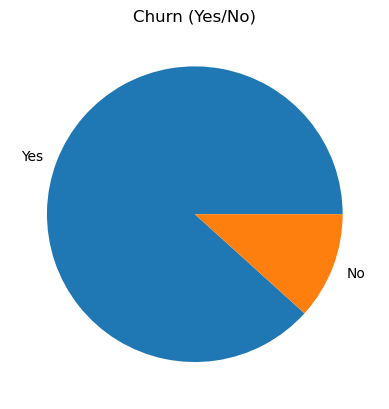

In [20]:
data["Churn"].value_counts().plot(kind="pie")
plt.title("Churn (Yes/No)")
plt.ylabel("")
plt.show()

Interpretation: The dataset contains considerably more churned customers than retained customers.

In [21]:
#Churn vs. Monthly Charges
data.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     62.54641
Yes    75.96077
Name: MonthlyCharges, dtype: float64

In [22]:
data.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     62.54641
Yes    75.96077
Name: MonthlyCharges, dtype: float64

In [23]:
#Churn, Gender, and Monthly Charges
data.groupby(["Churn","Gender"])["MonthlyCharges"].mean()

Churn  Gender
No     Female    65.091912
       Male      59.013878
Yes    Female    74.975064
       Male      77.082518
Name: MonthlyCharges, dtype: float64

In [24]:
#Churn vs. Tenure
data.groupby("Churn")["Tenure"].mean()

Churn
No     30.264957
Yes    17.476784
Name: Tenure, dtype: float64

In [25]:
#Churn vs. Age
data.groupby("Churn")["Age"].mean()

Churn
No     43.487179
Yes    44.831257
Name: Age, dtype: float64

At the lower terms we can see that the monthly charge average decreases

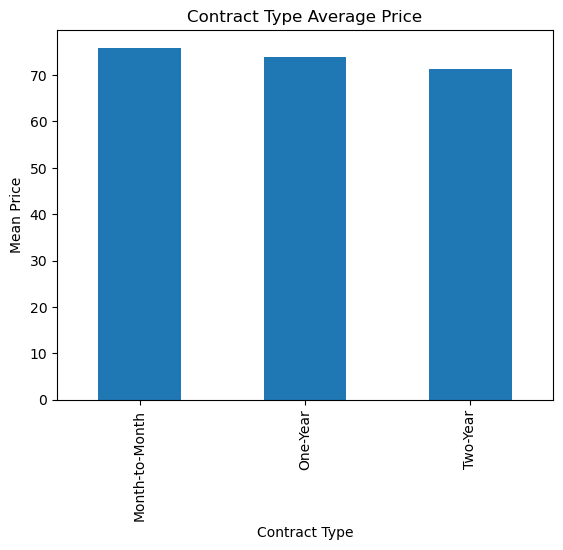

In [26]:
#Contract Type vs. Monthly Charges
data.groupby("ContractType")["MonthlyCharges"].mean().plot(kind="bar")
plt.ylabel("Mean Price")
plt.xlabel("Contract Type")
plt.title("Contract Type Average Price")
plt.show()

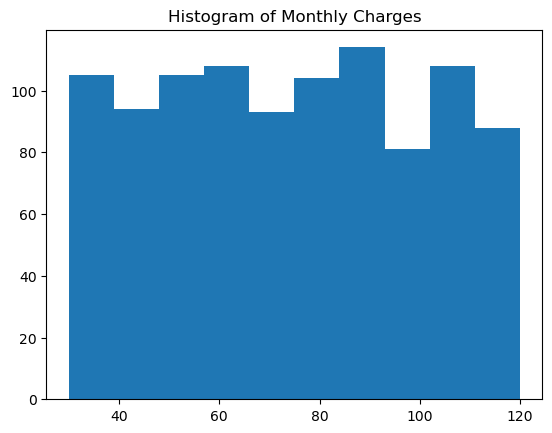

In [27]:
#Distribution of Monthly Charges
plt.hist(data["MonthlyCharges"])
plt.title("Histogram of Monthly Charges")
plt.show()

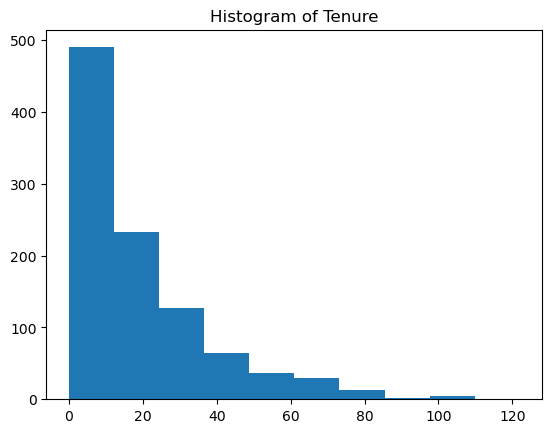

In [28]:
#Distribution of Tenure
plt.hist(data["Tenure"])
plt.title("Histogram of Tenure")
plt.show()

In [29]:
#Defining Input Features and Target Variable
y=data[["Churn"]]
X=data[["Age","Gender","Tenure","MonthlyCharges"]]

In [30]:
X # 1 Female & 0 male

,Age,Gender,Tenure,MonthlyCharges
0,49,Male,4,88.35
1,43,Male,0,36.67
2,51,Female,2,63.79
3,60,Female,8,102.34
4,42,Male,32,69.01
...,...,...,...,...
995,42,Male,41,37.14
996,62,Male,9,80.93
997,51,Female,15,111.72
998,39,Male,68,65.67


In [31]:
#Encoding the Gender Feature
X["Gender"]=X["Gender"].apply(lambda x:1 if x=="Female" else 0)

C:\Users\HP\AppData\Local\Temp\ipykernel_5132\1326180657.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["Gender"]=X["Gender"].apply(lambda x:1 if x=="Female" else 0)


Purpose: Convert the categorical gender values into numerical values.
Outcome:
- Female = 1
- Male = 0
Interpretation: The Gender column becomes numeric, allowing it to be used by the selected scikit-learn models.

In [32]:
y 

,Churn
0,Yes
1,Yes
2,Yes
3,Yes
4,Yes
...,...
995,Yes
996,Yes
997,Yes
998,Yes


In [33]:
type(X["Gender"][0])

numpy.int64

In [34]:
#Encoding the Target Variable
y["Churn"]=y["Churn"].apply(lambda x:1 if x=="Yes" else 0)

C:\Users\HP\AppData\Local\Temp\ipykernel_5132\1869447827.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y["Churn"]=y["Churn"].apply(lambda x:1 if x=="Yes" else 0)


Purpose: Convert the target into a binary numerical variable.
Outcome:
- Yes = 1
- No = 0
Interpretation: The model can now learn to classify customers into the two churn categories.

In [35]:
y.head() #1 yes & 0 No

,Churn
0,1
1,1
2,1
3,1
4,1


In [36]:
type(y["Churn"][0])

numpy.int64

**Train-Test Split**

In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Purpose: Divide the dataset into training and testing sets.
Outcome:
- Training set: 800 records (80%).
- Testing set: 200 records (20%).
Interpretation: The training set is used to fit the models, and the test set is used to evaluate their predictions.

In [38]:
X

,Age,Gender,Tenure,MonthlyCharges
0,49,0,4,88.35
1,43,0,0,36.67
2,51,1,2,63.79
3,60,1,8,102.34
4,42,0,32,69.01
...,...,...,...,...
995,42,0,41,37.14
996,62,0,9,80.93
997,51,1,15,111.72
998,39,0,68,65.67


In [39]:
#Importing StandardScaler
from sklearn.preprocessing import StandardScaler

In [40]:
scaler=StandardScaler()
#Outcome: The scaler is initialized and ready to be fitted on the training data.

In [41]:
#Scaling the Training Data
X_train =scaler.fit_transform(X_train)

Purpose: Learn the scaling parameters from the training data and transform the training features.
Outcome: The training features are standardized, which is useful for models such as Logistic Regression, KNN, and SVM.
Interpretation: Scaling puts features measured in different units onto a comparable scale.

In [42]:
#Saving the Scaler
import joblib
joblib.dump(scaler,"scaler.pkl")

['scaler.pkl']

In [43]:
X_test = scaler.transform(X_test)

In [44]:
X_train

array([[ 1.44680456e+00,  9.29947238e-01, -7.35371827e-01,
         2.70094630e-01],
       [ 2.07350359e-01,  9.29947238e-01, -5.24323410e-01,
        -1.66445141e+00],
       [ 6.20501760e-01,  9.29947238e-01,  2.48311653e+00,
        -8.17383568e-01],
       ...,
       [ 3.92571297e+00, -1.07532982e+00, -8.93658139e-01,
         4.39042135e-01],
       [ 7.74658877e-04, -1.07532982e+00,  5.83680777e-01,
         1.65701772e+00],
       [ 6.20501760e-01,  9.29947238e-01,  2.00825759e+00,
        -9.46715796e-01]], shape=(800, 4))

In [45]:
X_test

array([[-7.22240293e-01,  9.29947238e-01,  6.89204986e-01,
        -1.12420777e+00],
       [-1.34196739e+00,  9.29947238e-01,  2.67108152e-01,
        -6.63583080e-01],
       [-7.22240293e-01,  9.29947238e-01, -9.46420244e-01,
         3.35731707e-01],
       [ 7.74658877e-04,  9.29947238e-01, -8.93658139e-01,
        -1.88976524e-01],
       [-6.18952443e-01, -1.07532982e+00,  1.61583944e-01,
         6.38283677e-01],
       [ 1.34351671e+00, -1.07532982e+00, -6.29847619e-01,
         8.96171363e-01],
       [ 7.74658877e-04, -1.07532982e+00,  1.74444707e+00,
         1.27640035e+00],
       [-8.25528143e-01,  9.29947238e-01,  4.25394465e-01,
         8.08396337e-01],
       [ 7.74658877e-04,  9.29947238e-01, -5.77085514e-01,
         2.08729788e-01],
       [-8.25528143e-01,  9.29947238e-01, -4.71561306e-01,
        -1.56385967e+00],
       [ 1.65338026e+00,  9.29947238e-01, -1.02226577e-01,
        -1.17741653e+00],
       [-6.18952443e-01,  9.29947238e-01,  1.16406392e+00,
      

In [46]:
#Defining Model Evaluation
from sklearn.metrics import accuracy_score
def modelperformance(predictions):
    print("Accuracy score on model is {}".format(accuracy_score(y_test,predictions)))

#calculates accuracy by comparing actual test labels with predicted labels.

In [47]:
from sklearn.model_selection import GridSearchCV

**Logistic Regression**

In [89]:
from sklearn.linear_model import LogisticRegression

In [97]:
log_model= LogisticRegression(max_iter=1000, random_state=42)

In [91]:
import warnings
warnings.filterwarnings("ignore")

In [98]:
log_model.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [93]:
X

,Age,Gender,Tenure,MonthlyCharges
0,49,0,4,88.35
1,43,0,0,36.67
2,51,1,2,63.79
3,60,1,8,102.34
4,42,0,32,69.01
...,...,...,...,...
995,42,0,41,37.14
996,62,0,9,80.93
997,51,1,15,111.72
998,39,0,68,65.67


In [99]:
y_pred=log_model.predict(X_test)

In [100]:
modelperformance(y_pred)

Accuracy score on model is 0.875


Outcome : The model achieved 87.5% accuracy on the test set.

In [102]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
print("Logistic Regression")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))

Logistic Regression
Accuracy: 0.875
Precision: 0.8838383838383839
Recall: 0.9887005649717514
F1-score: 0.9333333333333333


F1-score of 93.33% is high, and the recall of 98.87% means your model catches nearly all customers who actually churn.

In [103]:
#Classification Report
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00        23
           1       0.88      0.99      0.93       177

    accuracy                           0.88       200
   macro avg       0.44      0.49      0.47       200
weighted avg       0.78      0.88      0.83       200



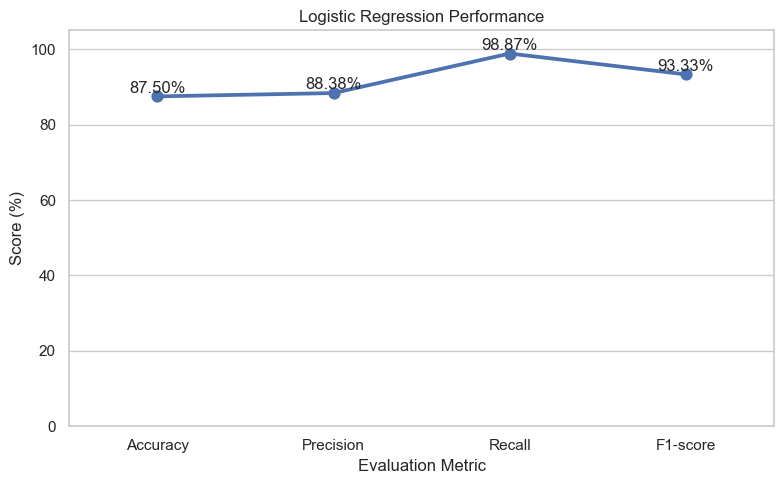

In [105]:
#Graphical Representation 
import seaborn as sns
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [87.5, 88.38, 98.87, 93.33]
})

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.pointplot(data=results, x="Metric", y="Score")

plt.ylim(0, 105)
plt.title("Logistic Regression Performance")
plt.ylabel("Score (%)")
plt.xlabel("Evaluation Metric")

for i, row in results.iterrows():
    plt.text(i, row["Score"] + 1, f'{row["Score"]:.2f}%',
             ha="center")

plt.tight_layout()
plt.show()

**KNN with GridSearchCV**

In [106]:
from sklearn.neighbors import KNeighborsClassifier

In [107]:
param_grid={
    "n_neighbors":[3,5,7,9],
    "weights":["uniform","distance"],
}

In [108]:
gridkn =GridSearchCV(KNeighborsClassifier(),param_grid,cv=5)

In [109]:
gridkn.fit(X_train,y_train)

,estimator,KNeighborsClassifier()
,param_grid,"{'n_neighbors': [3, 5, ...], 'weights': ['uniform', 'distance']}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_neighbors,7


In [110]:
gridkn.best_params_

{'n_neighbors': 7, 'weights': 'distance'}

In [111]:
y_pred=gridkn.predict(X_test)

In [112]:
modelperformance(y_pred)

Accuracy score on model is 0.865


In [113]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))

Accuracy: 0.865
Precision: 0.890625
Recall: 0.9661016949152542
F1-score: 0.926829268292683


KNN model has a high recall of 96.61%, meaning it catches most customers who actually churn. Its accuracy is 86.5%.

In [116]:
# Classification report
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.25      0.09      0.13        23
           1       0.89      0.97      0.93       177

    accuracy                           0.86       200
   macro avg       0.57      0.53      0.53       200
weighted avg       0.82      0.86      0.84       200



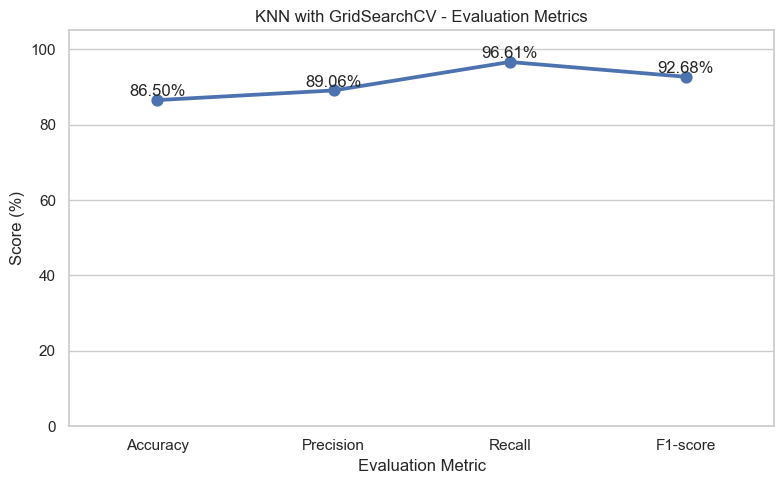

In [117]:
#Graphical Representation
knn_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [86.50, 89.06, 96.61, 92.68]
})

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))

sns.pointplot(
    data=knn_results,
    x="Metric",
    y="Score"
)

for i, row in knn_results.iterrows():
    plt.text(
        i, row["Score"] + 1,
        f'{row["Score"]:.2f}%',
        ha="center"
    )

plt.ylim(0, 105)
plt.title("KNN with GridSearchCV - Evaluation Metrics")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score (%)")
plt.tight_layout()
plt.show()

**Support Vector Machine (SVM)**

In [118]:
from sklearn.svm import SVC

In [119]:
svm= SVC()

In [120]:
param_grid={ 
    "C":[0.01,0.1,0.5,1],
    "kernel":["linear","rbf","poly"],
}

In [121]:
gridsvc= GridSearchCV(svm, param_grid, cv=5)

In [122]:
gridsvc.fit(X_train,y_train)

,estimator,SVC()
,param_grid,"{'C': [0.01, 0.1, ...], 'kernel': ['linear', 'rbf', ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,0.01


In [123]:
gridsvc.best_params_

{'C': 0.01, 'kernel': 'linear'}

In [124]:
y_pred=gridsvc.predict(X_test)

In [125]:
modelperformance(y_pred)

Accuracy score on model is 0.885


Recorded accuracy: 88.5%.
Interpretation: SVM achieved the highest recorded accuracy among the five models.

In [126]:
# Calculate metrics
print("SVM Evaluation Metrics")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))

SVM Evaluation Metrics
Accuracy: 0.885
Precision: 0.885
Recall: 1.0
F1-score: 0.9389920424403183


Based on these metrics, the SVM model shows strong performance, particularly in identifying churners. Further evaluation on unseen data is recommended before using it for real-world customer retention decisions.

In [128]:
#SVM classification report
print("SVM Classification Report")
print(classification_report(y_test, y_pred, zero_division=0))

SVM Classification Report
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        23
           1       0.89      1.00      0.94       177

    accuracy                           0.89       200
   macro avg       0.44      0.50      0.47       200
weighted avg       0.78      0.89      0.83       200



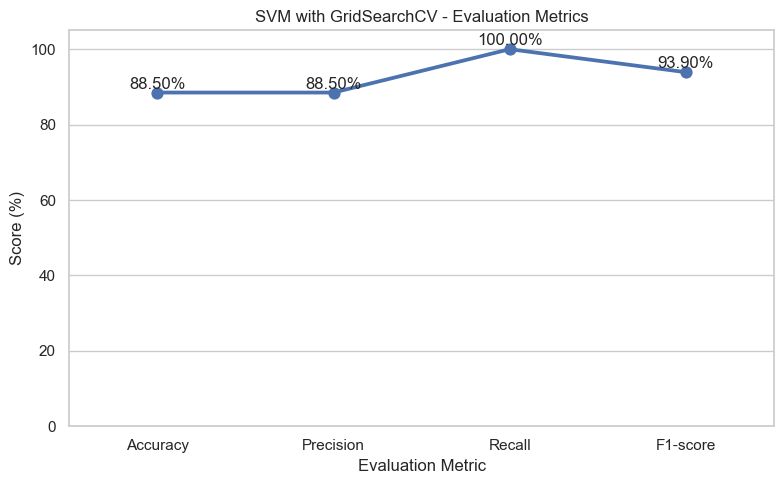

In [130]:
#graphical representation
svm_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [
        accuracy_score(y_test, y_pred) * 100,
        precision_score(y_test, y_pred, zero_division=0) * 100,
        recall_score(y_test, y_pred, zero_division=0) * 100,
        f1_score(y_test, y_pred, zero_division=0) * 100
    ]
})

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.pointplot(data=svm_results, x="Metric", y="Score")

for i, row in svm_results.iterrows():
    plt.text(i, row["Score"] + 1,
             f'{row["Score"]:.2f}%', ha="center")

plt.ylim(0, 105)
plt.title("SVM with GridSearchCV - Evaluation Metrics")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score (%)")
plt.tight_layout()
plt.show()

**Decision Tree Classifier**

In [131]:
from sklearn.tree import  DecisionTreeClassifier

In [132]:
param_grid={
    "criterion":["gini","entropy"],
    "splitter":["best","random"],
    "max_depth": [None ,10,20,30],
    "min_samples_split":[2,5,10],
    "min_samples_leaf":[1,2,4]
}

In [133]:
grid_tree=GridSearchCV(DecisionTreeClassifier() , param_grid, cv=5)

In [134]:
grid_tree.fit(X_train,y_train)

,estimator,DecisionTreeClassifier()
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': [None, 10, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'entropy'


In [135]:
grid_tree.best_params_

{'criterion': 'entropy',
 'max_depth': 10,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'splitter': 'random'}

In [136]:
y_pred=grid_tree.predict(X_test)

In [137]:
y_pred

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1,
       1, 1])

In [138]:
modelperformance(y_pred)

Accuracy score on model is 0.83


Interpretation: The selected Decision Tree configuration achieved the lowest recorded accuracy among the five models. This does not necessarily mean it will perform worst on every metric.

In [139]:
# Calculate metrics
print("Decision Tree Evaluation Metrics")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))

Decision Tree Evaluation Metrics
Accuracy: 0.83
Precision: 0.9132947976878613
Recall: 0.8926553672316384
F1-score: 0.9028571428571428


In [140]:
#Decision Tree classification report
print("Decision Tree Classification Report")
print(classification_report(y_test, y_pred, zero_division=0))

Decision Tree Classification Report
              precision    recall  f1-score   support

           0       0.30      0.35      0.32        23
           1       0.91      0.89      0.90       177

    accuracy                           0.83       200
   macro avg       0.60      0.62      0.61       200
weighted avg       0.84      0.83      0.84       200



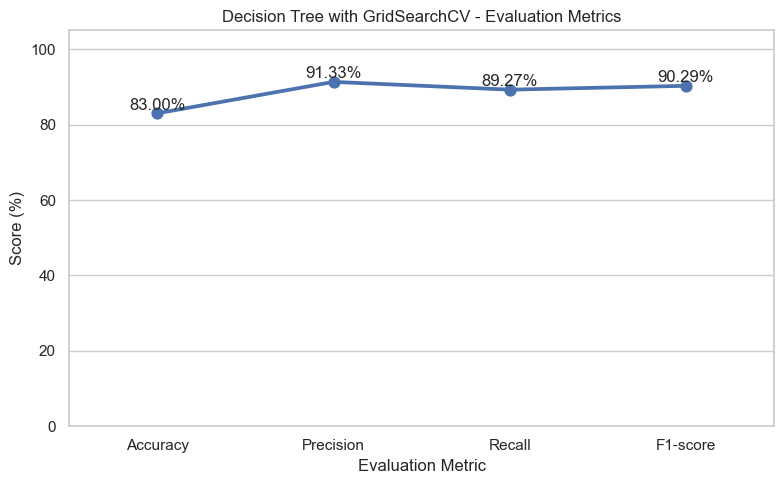

In [141]:
#Graphical Representation
dt_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [
        accuracy_score(y_test, y_pred) * 100,
        precision_score(y_test, y_pred, zero_division=0) * 100,
        recall_score(y_test, y_pred, zero_division=0) * 100,
        f1_score(y_test, y_pred, zero_division=0) * 100
    ]
})

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.pointplot(data=dt_results, x="Metric", y="Score")

for i, row in dt_results.iterrows():
    plt.text(i, row["Score"] + 1,
             f'{row["Score"]:.2f}%', ha="center")

plt.ylim(0, 105)
plt.title("Decision Tree with GridSearchCV - Evaluation Metrics")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score (%)")
plt.tight_layout()
plt.show()

**Random Forest Classifier**

In [142]:
from sklearn.ensemble import RandomForestClassifier
rfc_model=RandomForestClassifier()

In [143]:
param_grid= {
    "n_estimators":[32,64,128,256],
    "max_features": [2,3,4],
    "bootstrap":[True,False]
}

In [144]:
grid_rfc=GridSearchCV(rfc_model,param_grid,cv=5)

In [145]:
grid_rfc.fit(X_train,y_train)

,estimator,RandomForestClassifier()
,param_grid,"{'bootstrap': [True, False], 'max_features': [2, 3, ...], 'n_estimators': [32, 64, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,256


In [146]:
grid_rfc.best_params_

{'bootstrap': True, 'max_features': 2, 'n_estimators': 256}

In [147]:
y_pred=grid_rfc.predict(X_test)

In [148]:
modelperformance(y_pred)

Accuracy score on model is 0.87


Recorded accuracy: 87%.

Interpretation: The best configuration selected 256 trees, used two features at each split, and enabled bootstrap sampling.

In [149]:
# Calculate evaluation metrics
print("Random Forest Evaluation Metrics")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))

Random Forest Evaluation Metrics
Accuracy: 0.87
Precision: 0.8994708994708994
Recall: 0.96045197740113
F1-score: 0.9289617486338798


In [150]:
print("Random Forest Classification Report")
print(classification_report(y_test, y_pred, zero_division=0))

Random Forest Classification Report
              precision    recall  f1-score   support

           0       0.36      0.17      0.24        23
           1       0.90      0.96      0.93       177

    accuracy                           0.87       200
   macro avg       0.63      0.57      0.58       200
weighted avg       0.84      0.87      0.85       200



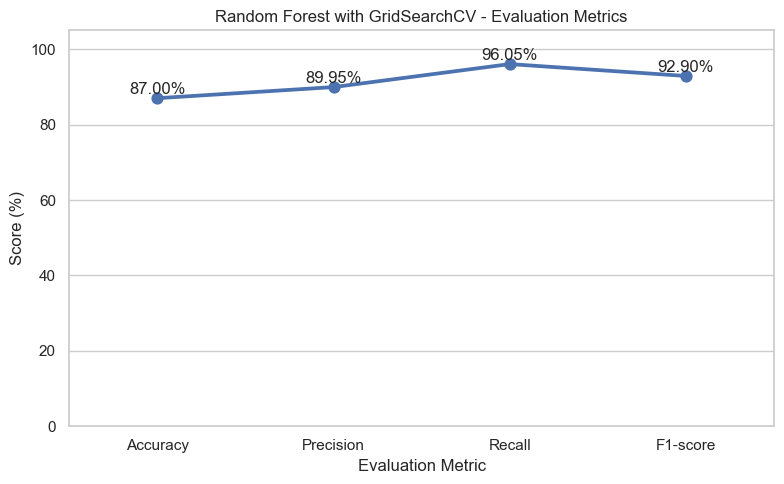

In [151]:
rf_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [
        accuracy_score(y_test, y_pred) * 100,
        precision_score(y_test, y_pred, zero_division=0) * 100,
        recall_score(y_test, y_pred, zero_division=0) * 100,
        f1_score(y_test, y_pred, zero_division=0) * 100
    ]
})

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.pointplot(data=rf_results, x="Metric", y="Score")

for i, row in rf_results.iterrows():
    plt.text(
        i, row["Score"] + 1,
        f'{row["Score"]:.2f}%',
        ha="center"
    )

plt.ylim(0, 105)
plt.title("Random Forest with GridSearchCV - Evaluation Metrics")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score (%)")
plt.tight_layout()
plt.show()

In [152]:
best_model=gridsvc.best_estimator_

In [153]:
accuracy_data = {
    "Model": [
        "Logistic Regression",
        "KNN",
        "SVM",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy (%)": [87.5, 86.5, 88.5, 83, 87]
}

accuracy_df = pd.DataFrame(accuracy_data)

display(accuracy_df)

,Model,Accuracy (%)
0,Logistic Regression,87.5
1,KNN,86.5
2,SVM,88.5
3,Decision Tree,83.0
4,Random Forest,87.0


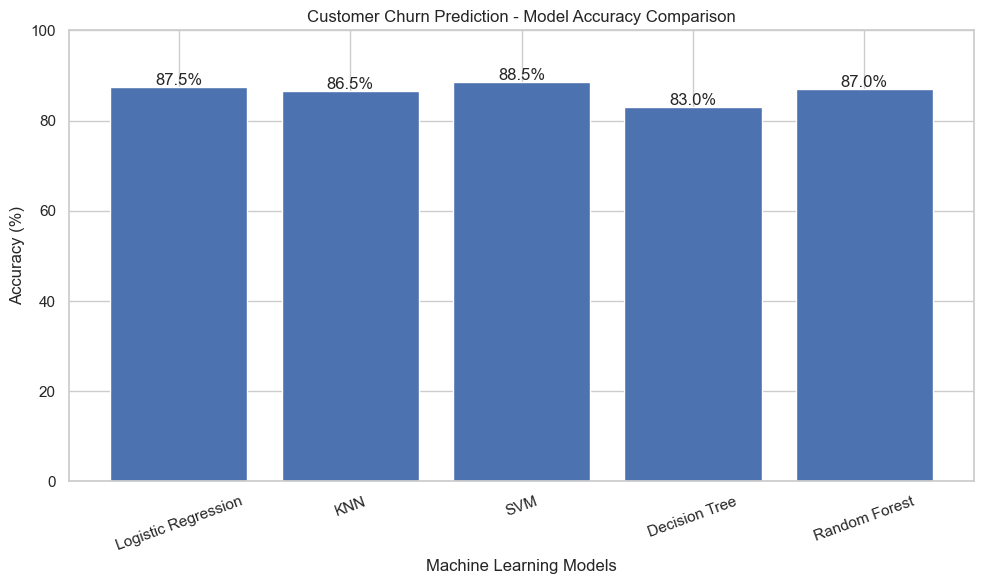

In [154]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    accuracy_df["Model"],
    accuracy_df["Accuracy (%)"]
)

plt.title("Customer Churn Prediction - Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20)

# Display accuracy values above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

SVM: highest recorded accuracy at 88.5%.
Decision Tree: lowest recorded accuracy at 83%.

**Customer Churn Prediction project, SVM (Support Vector Machine) is the best-performing model - recorded accuracy at 88.5%.**

In [163]:
import joblib
import os

# Save the trained SVM model
joblib.dump(gridsvc.best_estimator_, "svm_churn_model.pkl")

# Save the scaler
joblib.dump(scaler, "scaler.pkl")

# Check the saved files
print(os.listdir())

['!DOCTYPE html.txt', '.agents', '.anaconda', '.conda', '.continuum', '.gemini', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.keras', '.matplotlib', '.ms-ad', '.python_history', '.spss', '.streamlit', '.virtual_documents', '.vscode', '.vscode-shared', 'anaconda3', 'anaconda_projects', 'AppData', 'Application Data', 'archive.zip', 'bangalore_house_price_model.pkl', 'Car_Price_Prediction.ipynb', 'Cleaned_data.csv', 'clustered_df.csv', 'Contacts', 'Cookies', 'credict card.csv', 'Customer churn prediction.ipynb', 'customer_churn_data.csv', 'Customer_Churn_Prediction.ipynb', 'daily_weather.csv', 'daily_weather_with_high_humidity.csv', 'data.csv', 'Decision Tree(Practical_Implementation).ipynb', 'Diabetes prediction.ipynb', 'diabetes.csv', 'Documents', 'Downloads', 'education and career performance dataset.csv', 'Email_spam_classify_project.ipynb', 'Favorites', 'film_recommendation.ipynb', 'groupby.ipynb', 'Heart Desease Prediction.01.ipynb', 'heart disease predictiob.csv', 'HE

In [156]:
X.columns

Index(['Age', 'Gender', 'Tenure', 'MonthlyCharges'], dtype='object')

In [157]:
# Count churn and not-churn customers in test data
test_counts = y_test.value_counts()

total_test = len(y_test)

print("Total test customers:", total_test)
print("Churn customers:", test_counts.get(1, 0))
print("Not churn customers:", test_counts.get(0, 0))

print("Churn percentage:",
      round(test_counts.get(1, 0) / total_test * 100, 2), "%")

print("Not churn percentage:",
      round(test_counts.get(0, 0) / total_test * 100, 2), "%")

Total test customers: 200
Churn customers: 177
Not churn customers: 23
Churn percentage: 88.5 %
Not churn percentage: 11.5 %


**Graphical Representation-Churn vs Not Churn**

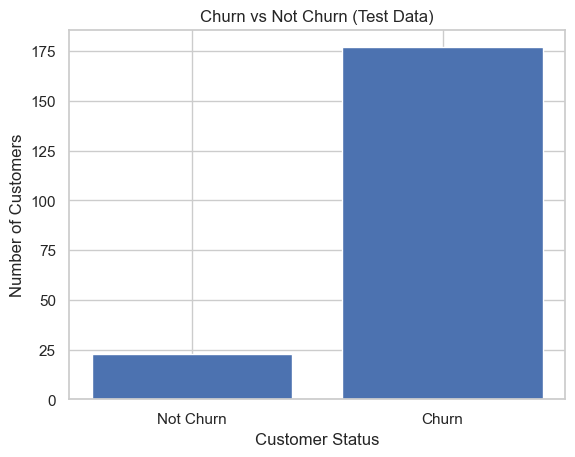

In [161]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Convert y_test into 1D
y = np.array(y_test).ravel()

# Count customers
counts = pd.Series(y).value_counts()

# If values are 0 and 1
not_churn = counts.get(0, 0)
churn = counts.get(1, 0)

# Simple bar graph
plt.bar(["Not Churn", "Churn"], [not_churn, churn])

plt.title("Churn vs Not Churn (Test Data)")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

plt.show()

**Findings of the Project**

The project analyzes customer churn and non-churn patterns in the telecommunications industry. It aims to identify customer characteristics associated with leaving or continuing to use the company's services. Customer details such as tenure, contract type, monthly charges, internet service, and technical support are examined to understand potential churn patterns.

Several Machine Learning algorithms are evaluated to predict customer churn. Among the five models compared, **Support Vector Machine (SVM) achieved the highest accuracy of 88.5%**, while **Decision Tree recorded the lowest accuracy of 83.0%**.

The results show that SVM performed best in terms of accuracy among the evaluated models, whereas Decision Tree had the lowest accuracy. However, the lowest accuracy does not necessarily mean the Decision Tree performed worst on every evaluation metric. Precision, recall, F1-score, and the confusion matrix should also be considered when comparing the models.

The predictions can help telecom companies identify customers who are at risk of leaving and develop suitable customer retention strategies to reduce customer loss and improve customer satisfaction.